# DSK805 Multivariate Statistical Analysis — Primate Molar Diet Classification


In [9]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


data_all = pd.read_csv("data.csv")
data_all

,DNE,positive_DNE,surface_area,positive_surface_area,Diet,Genus
0,0.134752,0.116051,0.002084,0.001754,NaN,Donrusselia
1,0.133532,0.115416,0.001998,0.001652,NaN,Donrusselia
2,0.131462,0.112864,0.001924,0.001626,NaN,Plesiadapidea
3,0.119059,0.104300,0.001925,0.001663,NaN,Plesiadapidea
4,0.153220,0.135459,0.002020,0.001727,NaN,Plesiadapidea
...,...,...,...,...,...,...
111,0.175600,0.154578,0.002172,0.001845,Frugivore-Folivore,Indridae
112,0.158839,0.139219,0.002066,0.001756,Frugivore-Folivore,Indridae
113,0.131423,0.119375,0.001752,0.001463,Frugivore-Folivore,Lemuridae
114,0.149479,0.129955,0.001994,0.001691,Frugivore-Folivore,Indridae


In [10]:
# Extract Frugivore-Folivore data

group_ff = data_all[data_all["Diet"] == "Frugivore-Folivore"].iloc[:,0:4]
group_ff

,DNE,positive_DNE,surface_area,positive_surface_area
78,0.144827,0.130705,0.001969,0.001720
79,0.133447,0.120155,0.001868,0.001625
80,0.141788,0.129903,0.001876,0.001610
81,0.125990,0.114392,0.001878,0.001634
105,0.163404,0.148247,0.001892,0.001605
106,0.140907,0.126794,0.001934,0.001675
107,0.150231,0.130957,0.002065,0.001757
108,0.149378,0.136580,0.001783,0.001505
109,0.134131,0.120191,0.001916,0.001608
110,0.143502,0.130223,0.001878,0.001591


In [11]:
# Extract Folivore data

group_f = data_all[data_all["Diet"] == "Folivore"].iloc[:,0:4]
group_f

,DNE,positive_DNE,surface_area,positive_surface_area
23,0.148635,0.134418,0.001969,0.001709
24,0.143896,0.132428,0.001883,0.001627
25,0.130280,0.118774,0.001849,0.001589
26,0.128199,0.118400,0.001797,0.001569
74,0.178004,0.154497,0.002301,0.001960
75,0.145688,0.131352,0.001937,0.001661
88,0.193009,0.165410,0.002336,0.002005
89,0.216026,0.189309,0.002418,0.002074
90,0.189634,0.162466,0.002310,0.001999
91,0.196669,0.165457,0.002356,0.002013


In [12]:
# Extract Omnivore data

group_o = data_all[data_all["Diet"] == "Omnivore"].iloc[:,0:4]
group_o

,DNE,positive_DNE,surface_area,positive_surface_area
7,0.118123,0.105877,0.001856,0.001584
8,0.124921,0.109731,0.001812,0.001515
21,0.108694,0.098958,0.001836,0.001626
22,0.142211,0.127103,0.001970,0.001683
29,0.142134,0.128563,0.001888,0.001600
30,0.147105,0.131927,0.001908,0.001614
31,0.138673,0.125629,0.001854,0.001555
40,0.130687,0.114456,0.001846,0.001561
53,0.129840,0.114372,0.001910,0.001619
54,0.147788,0.132364,0.001900,0.001598


In [13]:
# Extract Frugivore data

group_fr = data_all[data_all["Diet"] == "Frugivore"].iloc[:,0:4]
group_fr

,DNE,positive_DNE,surface_area,positive_surface_area
27,0.116771,0.105434,0.001676,0.001407
28,0.142915,0.131117,0.001792,0.001544
39,0.109806,0.105870,0.001550,0.001335
41,0.077254,0.072611,0.001517,0.001321
42,0.098963,0.091714,0.001586,0.001342
72,0.103193,0.093076,0.001780,0.001529
73,0.085696,0.077212,0.001746,0.001573
76,0.138096,0.127306,0.001759,0.001517
77,0.114783,0.105681,0.001734,0.001521


In [14]:
# Extract Insectivore data

group_i = data_all[data_all["Diet"] == "Insectivore"].iloc[:,0:4]
group_i

,DNE,positive_DNE,surface_area,positive_surface_area
5,0.167349,0.147907,0.002131,0.001820
6,0.161458,0.142538,0.002024,0.001722
9,0.162015,0.145451,0.002123,0.001836
17,0.217073,0.183808,0.002357,0.001989
18,0.213239,0.181925,0.002315,0.001940
19,0.211334,0.178729,0.002385,0.001991
20,0.224917,0.189961,0.002323,0.001925
32,0.180827,0.163275,0.002065,0.001785
33,0.187645,0.164668,0.002242,0.001886
34,0.167280,0.147625,0.002137,0.001836


In [15]:
# Box's M Test to deduce whether LDA can be used on this dataset
# (We get p-value < 0.05. This indicates that the covariance matrices of the 5 diet groups are significantly different. So, we should NOT use LDA, which assumes equal covariances.)

from scipy.stats import chi2

# Create group dictionary
groups = {
    "Frugivore-Folivore": group_ff,
    "Folivore": group_f,
    "Omnivore": group_o,
    "Frugivore": group_fr,
    "Insectivore": group_i
}

# Define Box’s M test function
def box_m_test_multiple(groups_dict):
    group_data = list(groups_dict.values())
    k = group_data[0].shape[1]  # number of variables
    g = len(group_data)         # number of groups

    cov_matrices = [np.cov(g.T, bias=False) for g in group_data]
    ns = [len(g) for g in group_data]
    
    pooled_cov = sum([(n - 1) * cov for n, cov in zip(ns, cov_matrices)]) / (sum(ns) - g)
    log_det_pooled = np.log(np.linalg.det(pooled_cov))
    log_dets = [np.log(np.linalg.det(cov)) for cov in cov_matrices]
    
    M = sum([(n - 1) * (log_det_pooled - ld) for n, ld in zip(ns, log_dets)])
    
    c = ((2 * k**2 + 3 * k - 1) / (6 * (k + 1) * (g - 1))) * (
        sum([1 / (n - 1) for n in ns]) - 1 / (sum(ns) - g)
    )
    
    chi_stat = M * (1 - c)
    df = (g - 1) * k * (k + 1) / 2
    p_value = 1 - chi2.cdf(chi_stat, df)
    
    return {
        "Box's M": M,
        "Chi-squared (adjusted)": chi_stat,
        "df": df,
        "p-value": p_value
    }

# Run the test
result = box_m_test_multiple(groups)

# Print the result
print("Box's M Test for All 5 Diet Groups:")
for key, value in result.items():
    print(f"{key}: {value:.4f}")

Box's M Test for All 5 Diet Groups:
Box's M: 104.1740
Chi-squared (adjusted): 89.4005
df: 40.0000
p-value: 0.0000


In [16]:
# Hotelling’s T² Test to deduce whether to merge the classes Frugivore-Folivore and Folivore
# (We get p-value > 0.05. So, we conclude that the mean vectors are equal. Therefore, we should merge the two classes.)

from scipy.stats import f

def hotelling_t2(X, Y):
    """Calculate Hotelling’s T² statistic for two samples."""
    n1, p = X.shape
    n2 = Y.shape[0]
    
    # Sample means
    mean_X = np.mean(X, axis=0)
    mean_Y = np.mean(Y, axis=0)
    
    # Pooled covariance matrix
    cov_X = np.cov(X, rowvar=False)
    cov_Y = np.cov(Y, rowvar=False)
    pooled_cov = ((n1 - 1) * cov_X + (n2 - 1) * cov_Y) / (n1 + n2 - 2)
    
    # Hotelling’s T²
    mean_diff = mean_X - mean_Y
    inv_pooled_cov = np.linalg.pinv(pooled_cov)
    t2 = (n1 * n2) / (n1 + n2) * mean_diff.T @ inv_pooled_cov @ mean_diff
    
    # Convert to F-statistic
    f_stat = (n1 + n2 - p - 1) / ((n1 + n2 - 2) * p) * t2
    p_value = 1 - f.cdf(f_stat, p, n1 + n2 - p - 1)
    
    return t2, f_stat, p_value

def permutation_hotelling(X, Y, n_permutations=9999):
    """Permutation test for Hotelling’s T²."""
    # Observed T²
    t2_obs, _, _ = hotelling_t2(X, Y)
    
    # Concatenate data
    Z = np.vstack((X, Y))
    n1 = X.shape[0]
    t2_perm = np.zeros(n_permutations)
    
    # Permutation loop
    for i in range(n_permutations):
        np.random.shuffle(Z)
        X_perm = Z[:n1]
        Y_perm = Z[n1:]
        t2_perm[i], _, _ = hotelling_t2(X_perm, Y_perm)
    
    # Calculate p-value
    p_value = (np.sum(t2_perm >= t2_obs) + 1) / (n_permutations + 1)
    
    return t2_obs, p_value

# Load your data (already done in your code)
group_ff = data_all[data_all["Diet"] == "Frugivore-Folivore"].iloc[:, 0:4].dropna()
group_f = data_all[data_all["Diet"] == "Folivore"].iloc[:, 0:4].dropna()

# Ensure same number of features
assert group_ff.shape[1] == group_f.shape[1], "Groups must have same number of features"

# Run permutation test
t2_obs, p_value = permutation_hotelling(group_ff.values, group_f.values)

print(f"Observed Hotelling’s T²: {t2_obs:.4f}")
print(f"Permutation p-value: {p_value:.4f}")

Observed Hotelling’s T²: 3.9317
Permutation p-value: 0.5040


In [17]:
# We merge the classes Frugivore-Folivore and Folivore of Diet column into the Folivore class

data_all['Diet'] = data_all['Diet'].replace('Frugivore-Folivore', 'Folivore')
data_all['Diet'].value_counts()

Diet
Folivore       27
Insectivore    25
Omnivore       13
Frugivore       9
Name: count, dtype: int64

In [18]:
# Remove rows with unknown Diet values from the training data
data = data_all.drop(index=range(0,5))
data = data.drop(index=range(10,17))
data = data.drop(index=range(55,71))
data = data.drop(index=range(82,86))
data = data.drop(index=87)
data = data.drop(index=range(92,96))
data = data.drop(index=range(98,103))

# New index created and old index dropped
data = data.reset_index()
data = data.drop(columns='index')
data

,DNE,positive_DNE,surface_area,positive_surface_area,Diet,Genus
0,0.167349,0.147907,0.002131,0.001820,Insectivore,Ptilocercus
1,0.161458,0.142538,0.002024,0.001722,Insectivore,Ptilocercus
2,0.118123,0.105877,0.001856,0.001584,Omnivore,Cheirogaleidae
3,0.124921,0.109731,0.001812,0.001515,Omnivore,Cheirogaleidae
4,0.162015,0.145451,0.002123,0.001836,Insectivore,Arctocebus
...,...,...,...,...,...,...
69,0.175600,0.154578,0.002172,0.001845,Folivore,Indridae
70,0.158839,0.139219,0.002066,0.001756,Folivore,Indridae
71,0.131423,0.119375,0.001752,0.001463,Folivore,Lemuridae
72,0.149479,0.129955,0.001994,0.001691,Folivore,Indridae


In [19]:
# Features extracted (Train data)

train_data = data.iloc[:,0:4]
train_data

,DNE,positive_DNE,surface_area,positive_surface_area
0,0.167349,0.147907,0.002131,0.001820
1,0.161458,0.142538,0.002024,0.001722
2,0.118123,0.105877,0.001856,0.001584
3,0.124921,0.109731,0.001812,0.001515
4,0.162015,0.145451,0.002123,0.001836
...,...,...,...,...
69,0.175600,0.154578,0.002172,0.001845
70,0.158839,0.139219,0.002066,0.001756
71,0.131423,0.119375,0.001752,0.001463
72,0.149479,0.129955,0.001994,0.001691


In [20]:
# Features scaled: (value - mean) / standard deviation

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
train_data_scaled = scaler.fit_transform(train_data)
train_data_scaled

array([[ 0.44829732,  0.45428655,  0.61621307,  0.63946378],
       [ 0.25917391,  0.2423924 ,  0.11557357,  0.0894246 ],
       [-1.13217326, -1.20426712, -0.67417743, -0.68900202],
       [-0.91392887, -1.05218742, -0.87994355, -1.07195143],
       [ 0.27704399,  0.35735955,  0.58045039,  0.7300511 ],
       [ 2.04477173,  1.87097979,  1.67792634,  1.58684534],
       [ 1.92168649,  1.79665141,  1.47856393,  1.31005599],
       [ 1.86050921,  1.67054456,  1.80682387,  1.599458  ],
       [ 2.29662957,  2.11378079,  1.51659281,  1.22606117],
       [-1.43490504, -1.4773188 , -0.76738585, -0.44958303],
       [-0.35879676, -0.36668495, -0.13816139, -0.1297012 ],
       [-0.15255506, -0.07802489, -0.14436641,  0.01333783],
       [-0.30468561, -0.15654507, -0.54713011, -0.44245547],
       [-0.74184292, -0.69535321, -0.70873269, -0.65759066],
       [-0.80868176, -0.71011213, -0.94969143, -0.77235518],
       [-1.17559978, -1.22175986, -1.52070509, -1.6805619 ],
       [-0.33617966, -0.

In [21]:
# Labels extracted

labels = data.iloc[:,4:5]
labels
# Flatten labels for scikit-learn estimators (keeps the displayed labels unchanged)
labels_1d = labels.to_numpy().ravel()


,Diet
0,Insectivore
1,Insectivore
2,Omnivore
3,Omnivore
4,Insectivore
...,...
69,Folivore
70,Folivore
71,Folivore
72,Folivore


In [22]:
# Features of Genus Teilhardina extracted (prediction data)

test_data = data_all.iloc[59:67, 0:4]
test_data

# New index created and old index dropped
test_data = test_data.reset_index()
test_data = test_data.drop(columns='index')
test_data

,DNE,positive_DNE,surface_area,positive_surface_area
0,0.115921,0.100504,0.001921,0.001621
1,0.127262,0.111552,0.001982,0.001677
2,0.129335,0.112564,0.001975,0.001682
3,0.116759,0.103174,0.001831,0.001556
4,0.116103,0.101067,0.001927,0.001642
5,0.134319,0.118678,0.001971,0.001672
6,0.116233,0.104005,0.001920,0.001646
7,0.117036,0.102553,0.001881,0.001595


In [23]:
# Prediction data scaled

test_data_scaled = scaler.transform(test_data)      # Important to use the same scaler that was used for the train data
test_data_scaled

array([[-1.20287535, -1.41630539, -0.37131908, -0.47710611],
       [-0.83876279, -0.98034919, -0.08259825, -0.16598772],
       [-0.77219328, -0.94040299, -0.11680831, -0.13765037],
       [-1.17598099, -1.31092272, -0.7916063 , -0.84280456],
       [-1.19703587, -1.39409734, -0.3422446 , -0.36218285],
       [-0.6121842 , -0.69913191, -0.13487098, -0.19441077],
       [-1.19286477, -1.27814062, -0.37519998, -0.34081505],
       [-1.16707851, -1.3354475 , -0.55873431, -0.62503134]])

In [24]:
# QDA 

from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

qda = QuadraticDiscriminantAnalysis(reg_param=0.01)
qda.fit(train_data_scaled, labels_1d)

labels_pred_qda = qda.predict(test_data_scaled)
labels_pred_qda

C:\Users\egok9\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


array(['Omnivore', 'Omnivore', 'Omnivore', 'Omnivore', 'Omnivore',
       'Omnivore', 'Omnivore', 'Omnivore'], dtype=object)

C:\Users\egok9\AppData\Local\Temp\ipykernel_24616\2986680201.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df_qda, x='Importance', y='Feature', palette='coolwarm')


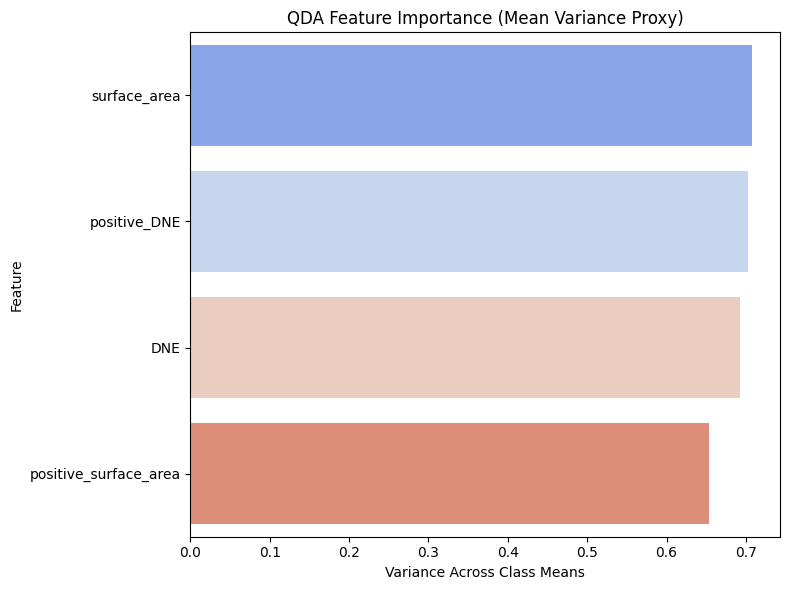

In [28]:
# Feature importance using QDA

# Get class means
qda_means = qda.means_

# Compute variance across class means for each feature
qda_importance = np.var(qda_means, axis=0)

# Create DataFrame for plotting
importance_df_qda = pd.DataFrame({
    'Feature': train_data.columns,
    'Importance': qda_importance
}).sort_values(by='Importance', ascending=False)

# Plot
plt.figure(figsize=(8, 6))
sns.barplot(data=importance_df_qda, x='Importance', y='Feature', palette='coolwarm')
plt.title('QDA Feature Importance (Mean Variance Proxy)')
plt.xlabel('Variance Across Class Means')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [25]:
# Hyperparameter tuning with QDA

# Define reg_param values to test
reg_params = [0.0, 0.01, 0.05, 0.1, 0.3, 0.5, 0.75, 1.0]

# Loop through each reg_param value
for i, reg_param in enumerate(reg_params):
    model = QuadraticDiscriminantAnalysis(reg_param=reg_param)
    model.fit(train_data_scaled, labels_1d)
    y_pred = model.predict(test_data_scaled)
    
    print(f"\nRun {i+1}: reg_param = {reg_param}")
    print("Predictions:", y_pred)


Run 1: reg_param = 0.0
Predictions: ['Folivore' 'Folivore' 'Folivore' 'Omnivore' 'Folivore' 'Omnivore'
 'Folivore' 'Omnivore']

Run 2: reg_param = 0.01
Predictions: ['Omnivore' 'Omnivore' 'Omnivore' 'Omnivore' 'Omnivore' 'Omnivore'
 'Omnivore' 'Omnivore']

Run 3: reg_param = 0.05
Predictions: ['Omnivore' 'Omnivore' 'Omnivore' 'Omnivore' 'Omnivore' 'Omnivore'
 'Omnivore' 'Omnivore']

Run 4: reg_param = 0.1
Predictions: ['Omnivore' 'Omnivore' 'Omnivore' 'Omnivore' 'Omnivore' 'Omnivore'
 'Omnivore' 'Omnivore']

Run 5: reg_param = 0.3
Predictions: ['Omnivore' 'Omnivore' 'Omnivore' 'Omnivore' 'Omnivore' 'Omnivore'
 'Omnivore' 'Omnivore']

Run 6: reg_param = 0.5
Predictions: ['Omnivore' 'Omnivore' 'Omnivore' 'Omnivore' 'Omnivore' 'Folivore'
 'Omnivore' 'Omnivore']

Run 7: reg_param = 0.75
Predictions: ['Omnivore' 'Folivore' 'Folivore' 'Omnivore' 'Omnivore' 'Folivore'
 'Omnivore' 'Omnivore']

Run 8: reg_param = 1.0
Predictions: ['Omnivore' 'Folivore' 'Folivore' 'Omnivore' 'Omnivore' 'Folivor

C:\Users\egok9\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\Users\egok9\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
C:\Users\egok9\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\utils\validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the sha

In [26]:
# Random Forest

from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=200, min_samples_split=5)
rf.fit(train_data_scaled, labels_1d)

labels_pred_rf = rf.predict(test_data_scaled)
labels_pred_rf

C:\Users\egok9\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\sklearn\base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)


array(['Omnivore', 'Omnivore', 'Omnivore', 'Omnivore', 'Omnivore',
       'Folivore', 'Omnivore', 'Omnivore'], dtype=object)

C:\Users\egok9\AppData\Local\Temp\ipykernel_24616\92357794.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=importance_df_rf, x='Importance', y='Feature', palette='viridis')


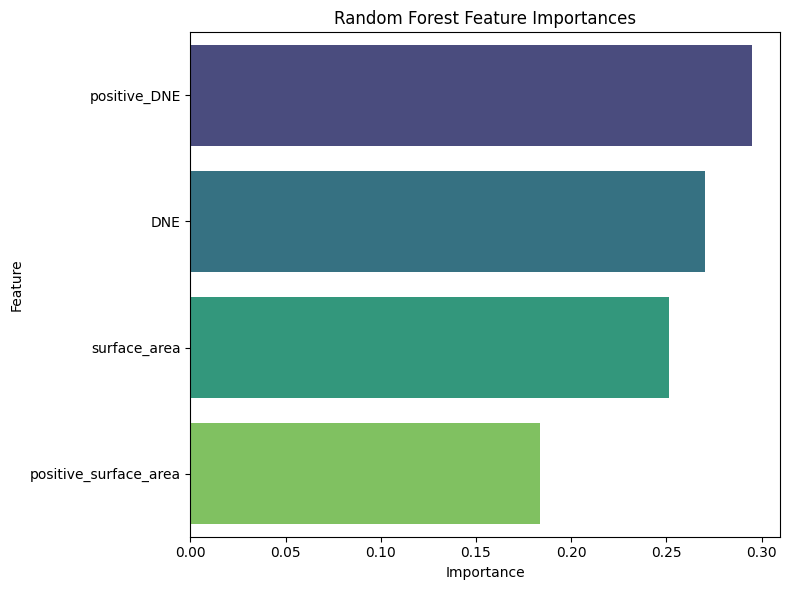

In [27]:
# Feature importance using Random Forest

# Assuming you have already fitted your Random Forest model and feature names
feature_names = train_data.columns
importances_rf = rf.feature_importances_

# Create DataFrame for plotting
importance_df_rf = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances_rf
}).sort_values(by='Importance', ascending=False)

# Plot
plt.figure(figsize=(8, 6))
sns.barplot(data=importance_df_rf, x='Importance', y='Feature', palette='viridis')
plt.title('Random Forest Feature Importances')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

In [ ]:
# Hyperparameter tuning with Random Forest

import itertools

# Define parameter grid
n_estimators_list = [10, 50, 100, 200]
max_depth_list = [2, 3, None]
min_samples_split_list = [2, 3, 4, 5]
max_features_list = ['sqrt', 'log2']

# Create all combinations
param_grid = list(itertools.product(n_estimators_list, max_depth_list, min_samples_split_list, max_features_list))

# Loop through each combination
for i, (n_estimators, max_depth, min_samples_split, max_features) in enumerate(param_grid):
    model = RandomForestClassifier(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_split=min_samples_split,
        max_features=max_features,
        random_state=42
    )
    model.fit(train_data_scaled, labels_1d)
    y_pred = model.predict(test_data_scaled)
    
    print(f"\nRun {i+1}: n_estimators={n_estimators}, max_depth={max_depth}, "
          f"min_samples_split={min_samples_split}, max_features={max_features}")
    print("Predictions:", y_pred)